In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import os
ruta_carpeta = '/content/drive/MyDrive/Tp5 Accidentes'
print(os.listdir(ruta_carpeta))

['accident_data.csv']


In [12]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Tp5_Accidentes/accident_data.csv')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [13]:
import pandas as pd
from google.colab import drive
drive.mount('/content/drive')

df = pd.read_csv('/content/drive/MyDrive/Tp5_Accidentes/accident_data.csv')

print(df.shape)
print(df.dtypes)
print(df.head(3).T)
print(df.isnull().sum())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
(670679, 14)
Index                       object
Accident_Severity           object
Accident Date               object
Latitude                   float64
Light_Conditions            object
District Area               object
Longitude                  float64
Number_of_Casualties         int64
Number_of_Vehicles           int64
Road_Surface_Conditions     object
Road_Type                   object
Urban_or_Rural_Area         object
Weather_Conditions          object
Vehicle_Type                object
dtype: object
                                              0                       1  \
Index                             200701BS64157           200701BS65737   
Accident_Severity                       Serious                 Serious   
Accident Date                        05-06-2019              02-07-2019   
Latitude                              51.506187       

In [14]:
print("Filas y columnas:", df.shape)
print()
df.info()

Filas y columnas: (670679, 14)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 670679 entries, 0 to 670678
Data columns (total 14 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Index                    670679 non-null  object 
 1   Accident_Severity        670679 non-null  object 
 2   Accident Date            670679 non-null  object 
 3   Latitude                 670654 non-null  float64
 4   Light_Conditions         670679 non-null  object 
 5   District Area            670679 non-null  object 
 6   Longitude                670653 non-null  float64
 7   Number_of_Casualties     670679 non-null  int64  
 8   Number_of_Vehicles       670679 non-null  int64  
 9   Road_Surface_Conditions  669937 non-null  object 
 10  Road_Type                666099 non-null  object 
 11  Urban_or_Rural_Area      670664 non-null  object 
 12  Weather_Conditions       656328 non-null  object 
 13  Vehicle_Type             67

In [15]:
nulos = df.isnull().sum()
porcentaje = (nulos / len(df) * 100).round(2)
resumen_nulos = pd.DataFrame({'nulos': nulos, '% nulos': porcentaje})
print(resumen_nulos[resumen_nulos['nulos'] > 0].sort_values('% nulos', ascending=False))

                         nulos  % nulos
Weather_Conditions       14351     2.14
Road_Type                 4580     0.68
Road_Surface_Conditions    742     0.11
Latitude                    25     0.00
Longitude                   26     0.00
Urban_or_Rural_Area         15     0.00


In [16]:
print("Filas duplicadas:", df.duplicated().sum())

Filas duplicadas: 19


In [17]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Latitude,670654.0,52.554015,1.406956,49.914430,51.490672,52.316381,53.453395,60.757544
Longitude,670653.0,-1.431468,1.383224,-7.516225,-2.332413,-1.411817,-0.233365,1.762010
Number_of_Casualties,670679.0,1.357013,0.824759,1.000000,1.000000,1.000000,1.000000,68.000000
Number_of_Vehicles,670679.0,1.831237,0.715443,1.000000,1.000000,2.000000,2.000000,32.000000


In [18]:
cat_cols = df.select_dtypes(include='object').columns
for c in cat_cols:
    print(f"\n--- {c} ({df[c].nunique()} valores distintos) ---")
    print(df[c].value_counts().head(8))


--- Index (431020 valores distintos) ---
Index
2.01E+12     239478
2.01E+260         4
2.01E+86          4
2.01E+98          4
2.01E+199         4
2.01E+197         4
2.01E+239         4
2.01E+175         4
Name: count, dtype: int64

--- Accident_Severity (3 valores distintos) ---
Accident_Severity
Slight     572307
Serious     89568
Fatal        8804
Name: count, dtype: int64

--- Accident Date (2556 valores distintos) ---
Accident Date
30-11-2019    704
31-01-2019    697
13-11-2021    692
13-07-2019    692
14-08-2019    688
11-02-2021    685
06-10-2021    680
28-09-2019    679
Name: count, dtype: int64

--- Light_Conditions (5 valores distintos) ---
Light_Conditions
Daylight                       492201
Darkness - lights lit          131333
Darkness - no lighting          37981
Darkness - lighting unknown      6583
Darkness - lights unlit          2581
Name: count, dtype: int64

--- District Area (422 valores distintos) ---
District Area
Birmingham      13701
Leeds            9027
M

In [19]:
print(list(df.columns))

['Index', 'Accident_Severity', 'Accident Date', 'Latitude', 'Light_Conditions', 'District Area', 'Longitude', 'Number_of_Casualties', 'Number_of_Vehicles', 'Road_Surface_Conditions', 'Road_Type', 'Urban_or_Rural_Area', 'Weather_Conditions', 'Vehicle_Type']


In [20]:
# Copia para no modificar el original
df_limpio = df.copy()

# 1. Eliminar la columna Index (identificador sin valor predictivo)
df_limpio = df_limpio.drop(columns=['Index'])

# 2. Eliminar duplicados
antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates()
print("Duplicados eliminados:", antes - len(df_limpio))

# 3. Eliminar filas sin coordenadas
antes = len(df_limpio)
df_limpio = df_limpio.dropna(subset=['Latitude', 'Longitude'])
print("Filas sin coordenadas eliminadas:", antes - len(df_limpio))

# 4. Nulos categóricos -> "Desconocido"
for c in ['Weather_Conditions', 'Road_Type', 'Road_Surface_Conditions', 'Urban_or_Rural_Area']:
    df_limpio[c] = df_limpio[c].fillna('Desconocido')

print("Forma final:", df_limpio.shape)
print("Nulos restantes:", df_limpio.isnull().sum().sum())

Duplicados eliminados: 52
Filas sin coordenadas eliminadas: 26
Forma final: (670601, 13)
Nulos restantes: 0


In [22]:
# Copia para no modificar el original
df_limpio = df.copy()

# 1. Eliminar duplicados EXACTOS primero (con todas las columnas originales)
antes = len(df_limpio)
df_limpio = df_limpio.drop_duplicates()
print("Duplicados eliminados:", antes - len(df_limpio))

# 2. Eliminar columnas que no usaremos
df_limpio = df_limpio.drop(columns=['Index', 'Latitude', 'Longitude', 'District Area'])

# 3. Nulos categóricos -> "Desconocido"
for c in ['Weather_Conditions', 'Road_Type', 'Road_Surface_Conditions', 'Urban_or_Rural_Area']:
    df_limpio[c] = df_limpio[c].fillna('Desconocido')

# 4. Fecha -> solo el mes
df_limpio['Accident Date'] = pd.to_datetime(df_limpio['Accident Date'], format='%d-%m-%Y')
df_limpio['Mes'] = df_limpio['Accident Date'].dt.month
df_limpio = df_limpio.drop(columns=['Accident Date'])

print("Forma final:", df_limpio.shape)
print("Nulos restantes:", df_limpio.isnull().sum().sum())
print(df_limpio['Accident_Severity'].value_counts(normalize=True).round(3))

Duplicados eliminados: 19
Forma final: (670660, 10)
Nulos restantes: 0
Accident_Severity
Slight     0.853
Serious    0.134
Fatal      0.013
Name: proportion, dtype: float64


In [23]:
def agrupar_vehiculo(v):
    v = str(v).lower()
    if 'motorcycle' in v:
        return 'Moto'
    if 'car' in v or 'taxi' in v:
        return 'Auto'
    if 'van' in v or 'goods' in v:
        return 'Furgoneta/Camión'
    if 'bus' in v or 'coach' in v or 'minibus' in v:
        return 'Bus'
    return 'Otro'

df_limpio['Vehicle_Group'] = df_limpio['Vehicle_Type'].apply(agrupar_vehiculo)

# Verificación: cómo quedó cada grupo
print(df_limpio['Vehicle_Group'].value_counts())
print()
print(df_limpio[df_limpio['Vehicle_Group'] == 'Otro']['Vehicle_Type'].value_counts())

Vehicle_Group
Auto                518980
Furgoneta/Camión     58461
Moto                 57027
Bus                  28283
Otro                  7909
Name: count, dtype: int64

Vehicle_Type
Other vehicle                   5714
Agricultural vehicle            1983
Pedal cycle                      201
Data missing or out of range       7
Ridden horse                       4
Name: count, dtype: int64


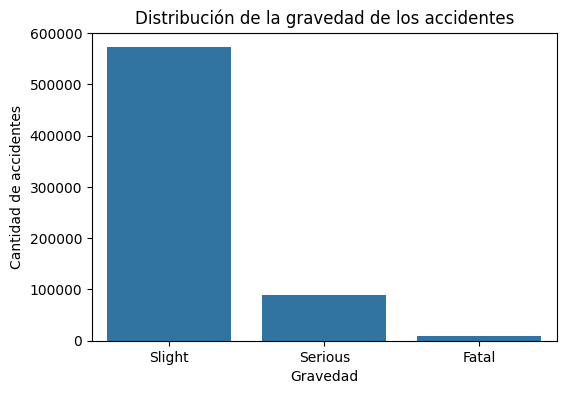

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

orden = ['Slight', 'Serious', 'Fatal']
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df_limpio, x='Accident_Severity', order=orden)
ax.set_title('Distribución de la gravedad de los accidentes')
ax.set_xlabel('Gravedad')
ax.set_ylabel('Cantidad de accidentes')
plt.show()

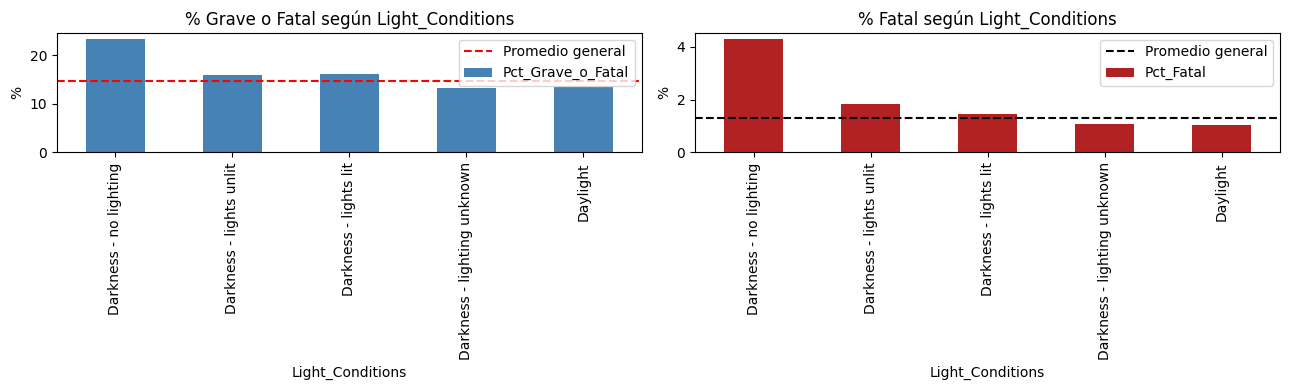

                             Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Light_Conditions                                                     
Darkness - no lighting            37976       4.31              23.50
Darkness - lights unlit            2581       1.82              15.92
Darkness - lights lit            131333       1.44              16.25
Darkness - lighting unknown        6583       1.06              13.32
Daylight                         492187       1.05              13.58



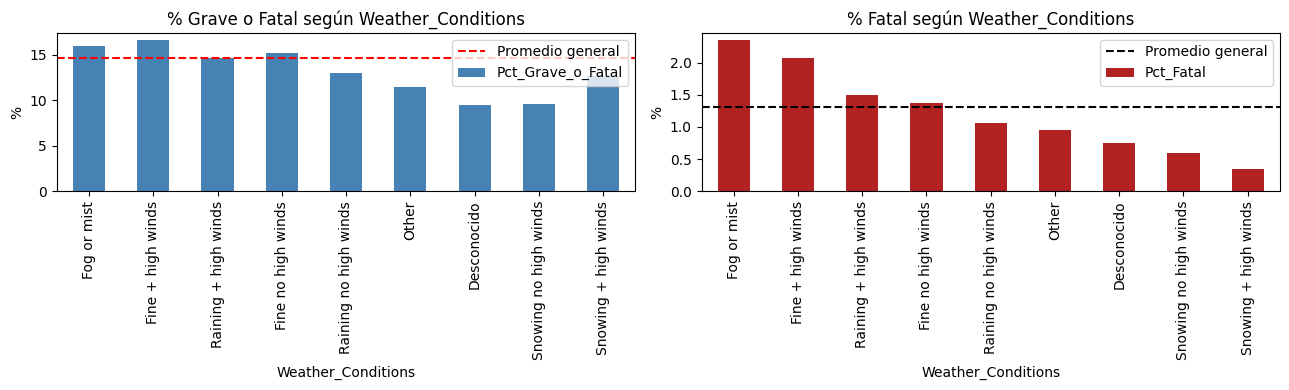

                       Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Weather_Conditions                                             
Fog or mist                  3575       2.35              15.94
Fine + high winds            8694       2.08              16.61
Raining + high winds         9755       1.50              14.67
Fine no high winds         528776       1.37              15.20
Raining no high winds       80893       1.06              12.96
Other                       17384       0.95              11.45
Desconocido                 14350       0.75               9.49
Snowing no high winds        6339       0.60               9.65
Snowing + high winds          894       0.34              12.64



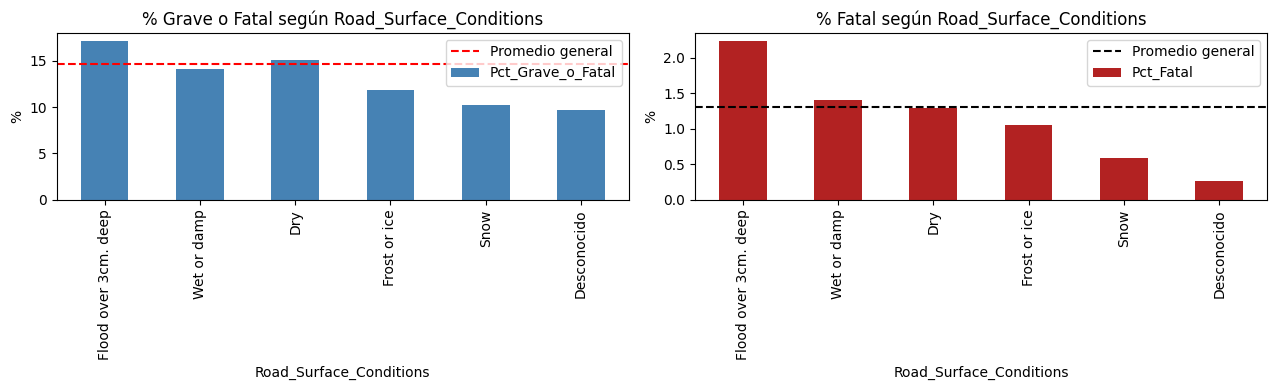

                         Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Road_Surface_Conditions                                          
Flood over 3cm. deep           1025       2.24              17.17
Wet or damp                  189522       1.40              14.16
Dry                          454582       1.29              15.06
Frost or ice                  18808       1.05              11.90
Snow                           5981       0.59              10.20
Desconocido                     742       0.27               9.70



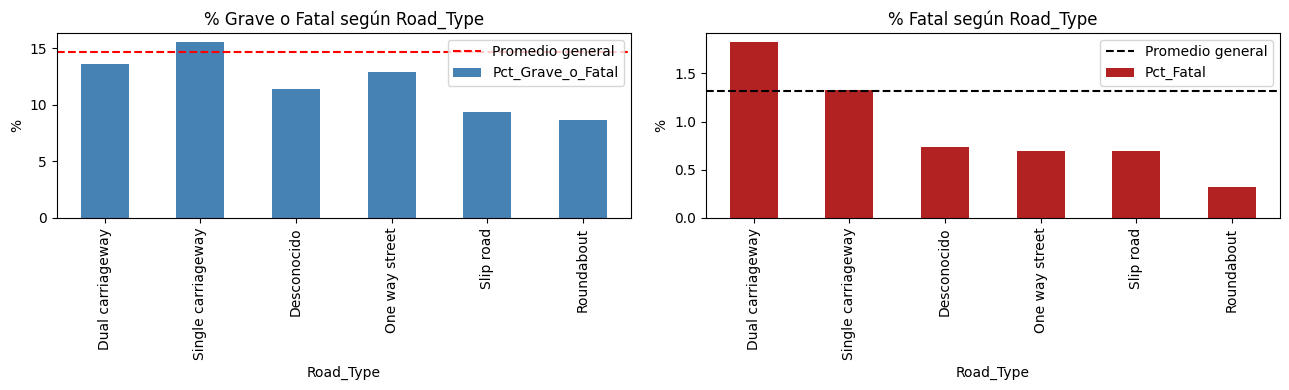

                    Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Road_Type                                                   
Dual carriageway        100918       1.83              13.64
Single carriageway      499599       1.33              15.57
Desconocido               4580       0.74              11.40
One way street           13769       0.69              12.91
Slip road                 7143       0.69               9.38
Roundabout               44651       0.32               8.64



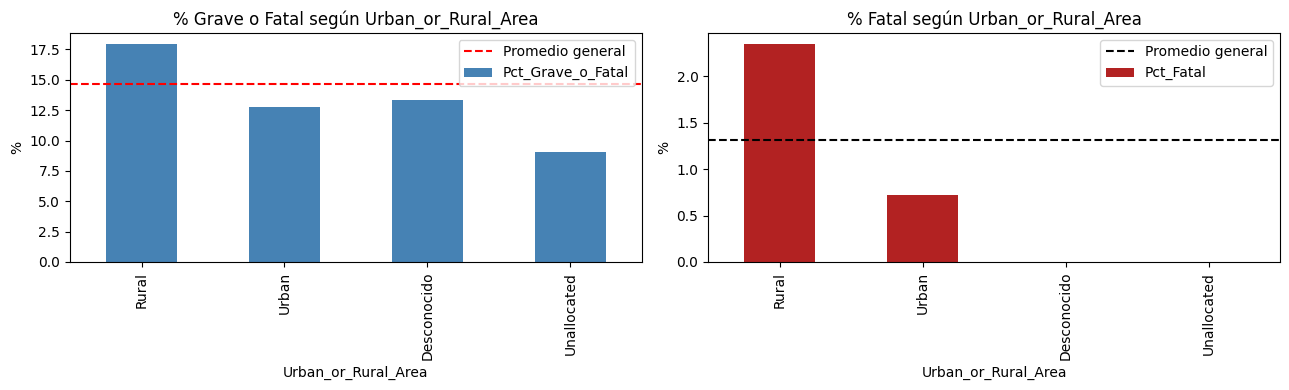

                     Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Urban_or_Rural_Area                                          
Rural                    242599       2.35              17.97
Urban                    428035       0.72              12.80
Desconocido                  15       0.00              13.33
Unallocated                  11       0.00               9.09



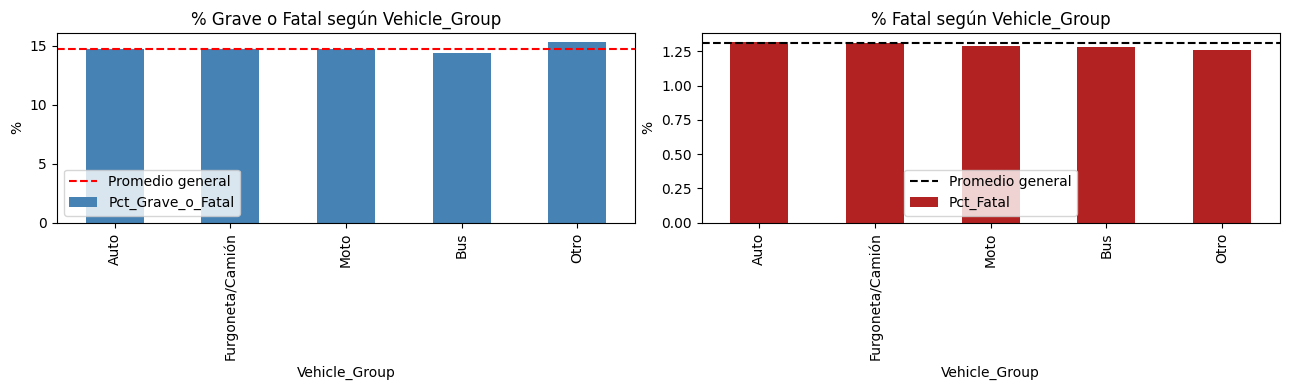

                  Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Vehicle_Group                                             
Auto                  518980       1.32              14.67
Furgoneta/Camión       58461       1.31              14.73
Moto                   57027       1.29              14.67
Bus                    28283       1.28              14.38
Otro                    7909       1.26              15.31



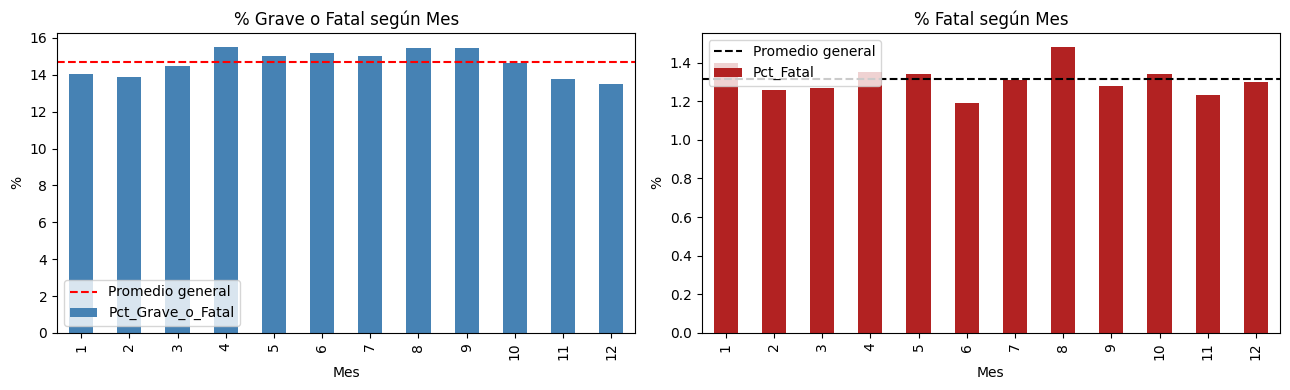

     Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Mes                                          
1         53691       1.40              14.06
2         50242       1.26              13.87
3         54916       1.27              14.45
4         52589       1.35              15.50
5         57183       1.34              15.04
6         57303       1.19              15.19
7         58302       1.31              15.01
8         54728       1.48              15.45
9         57285       1.28              15.45
10        60494       1.34              14.65
11        61333       1.23              13.75
12        52594       1.30              13.49



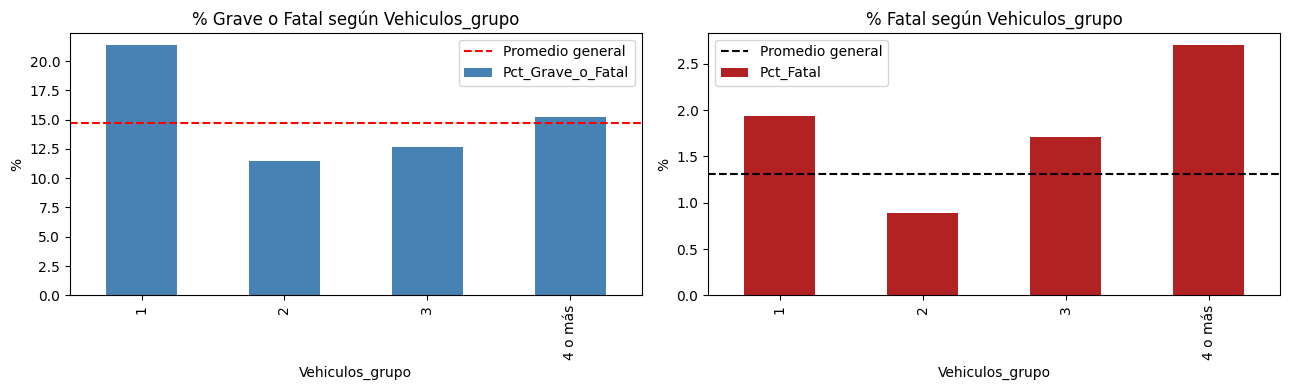

                 Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Vehiculos_grupo                                          
1                    203811       1.94              21.34
2                    397950       0.89              11.50
3                     53589       1.71              12.69
4 o más               15310       2.70              15.21



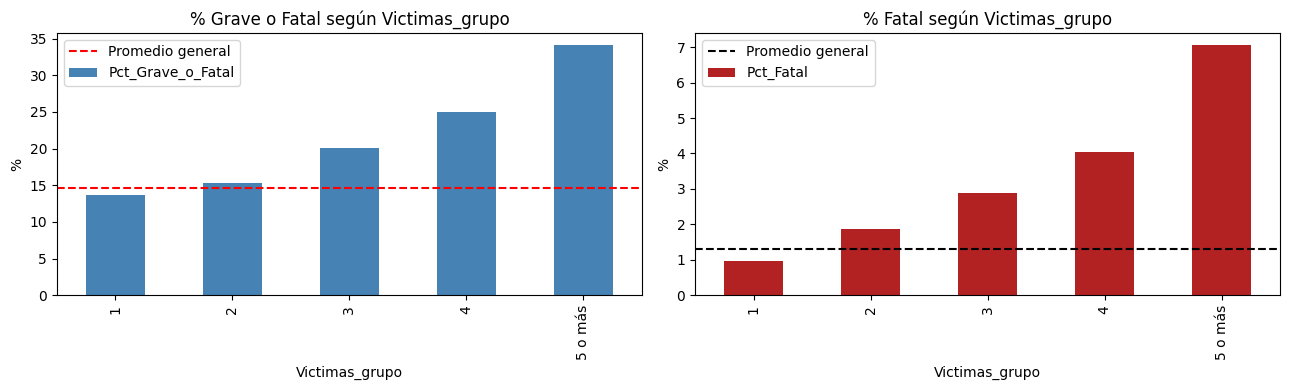

                Accidentes  Pct_Fatal  Pct_Grave_o_Fatal
Victimas_grupo                                          
1                   511666       0.96              13.72
2                   109601       1.86              15.30
3                    31240       2.88              20.02
4                    11313       4.05              25.04
5 o más               6840       7.05              34.08



In [25]:
# Variables auxiliares agrupadas (solo para el EDA)
df_limpio['Vehiculos_grupo'] = df_limpio['Number_of_Vehicles'].clip(upper=4).astype(str).replace('4', '4 o más')
df_limpio['Victimas_grupo'] = df_limpio['Number_of_Casualties'].clip(upper=5).astype(str).replace('5', '5 o más')

df_limpio['Es_Fatal'] = (df_limpio['Accident_Severity'] == 'Fatal').astype(int)
df_limpio['Es_Grave_o_Fatal'] = df_limpio['Accident_Severity'].isin(['Serious', 'Fatal']).astype(int)

prom_fatal = df_limpio['Es_Fatal'].mean() * 100
prom_grave = df_limpio['Es_Grave_o_Fatal'].mean() * 100

def analizar(col, orden=None):
    t = df_limpio.groupby(col).agg(
        Accidentes=('Es_Fatal', 'size'),
        Pct_Fatal=('Es_Fatal', lambda x: x.mean() * 100),
        Pct_Grave_o_Fatal=('Es_Grave_o_Fatal', lambda x: x.mean() * 100)
    ).round(2)
    if orden is not None:
        t = t.reindex(orden)
    else:
        t = t.sort_values('Pct_Fatal', ascending=False)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    t['Pct_Grave_o_Fatal'].plot(kind='bar', ax=axes[0], color='steelblue')
    axes[0].axhline(prom_grave, color='red', linestyle='--', label='Promedio general')
    axes[0].set_title(f'% Grave o Fatal según {col}')
    axes[0].set_ylabel('%')
    axes[0].legend()

    t['Pct_Fatal'].plot(kind='bar', ax=axes[1], color='firebrick')
    axes[1].axhline(prom_fatal, color='black', linestyle='--', label='Promedio general')
    axes[1].set_title(f'% Fatal según {col}')
    axes[1].set_ylabel('%')
    axes[1].legend()

    plt.tight_layout()
    plt.show()
    print(t)
    print()

for col in ['Light_Conditions', 'Weather_Conditions', 'Road_Surface_Conditions',
            'Road_Type', 'Urban_or_Rural_Area', 'Vehicle_Group']:
    analizar(col)

analizar('Mes', orden=list(range(1, 13)))
analizar('Vehiculos_grupo', orden=['1', '2', '3', '4 o más'])
analizar('Victimas_grupo', orden=['1', '2', '3', '4', '5 o más'])

In [26]:
from sklearn.model_selection import train_test_split

# 1. Variables de entrada y objetivo
features = ['Light_Conditions', 'Weather_Conditions', 'Road_Surface_Conditions',
            'Road_Type', 'Urban_or_Rural_Area']
df_modelo = df_limpio[features + ['Accident_Severity']].copy()

# 2. Sacar las pocas filas sin zona definida
df_modelo = df_modelo[~df_modelo['Urban_or_Rural_Area'].isin(['Unallocated', 'Desconocido'])]

# 3. Codificación one-hot de las variables categóricas
X = pd.get_dummies(df_modelo[features], drop_first=True)
y = df_modelo['Accident_Severity']

# 4. Separar entrenamiento (80%) y prueba (20%), manteniendo la proporción de clases
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

print("X:", X.shape)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)
print(y_train.value_counts(normalize=True).round(3))

# 5. Guardar los datos preparados en Drive
ruta = '/content/drive/MyDrive/Tp5_Accidentes/'
df_modelo.to_csv(ruta + 'datos_modelo.csv', index=False)

X: (670634, 23)
Entrenamiento: (536507, 23) | Prueba: (134127, 23)
Accident_Severity
Slight     0.853
Serious    0.134
Fatal      0.013
Name: proportion, dtype: float64


Random Forest entrenado en 14 s
Regresión Logística entrenada en 19 s


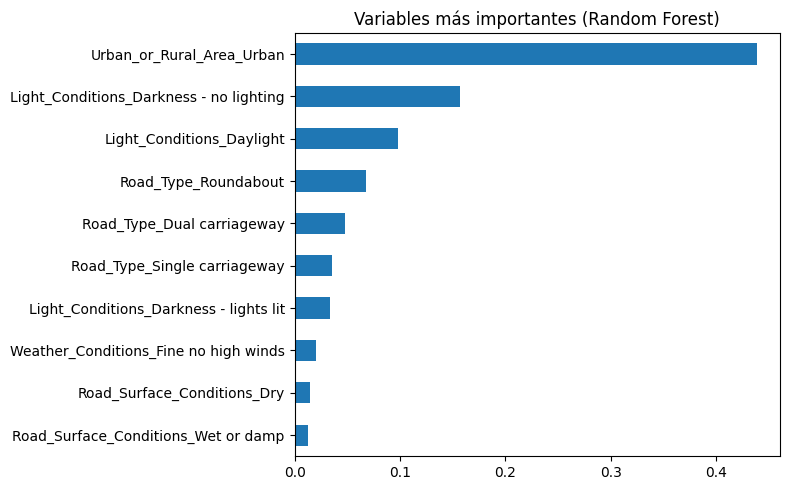

Urban_or_Rural_Area_Urban                  0.439
Light_Conditions_Darkness - no lighting    0.157
Light_Conditions_Daylight                  0.098
Road_Type_Roundabout                       0.068
Road_Type_Dual carriageway                 0.048
Road_Type_Single carriageway               0.035
Light_Conditions_Darkness - lights lit     0.034
Weather_Conditions_Fine no high winds      0.021
Road_Surface_Conditions_Dry                0.015
Road_Surface_Conditions_Wet or damp        0.013
dtype: float64


In [27]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
import time

# Modelo 1: Random Forest
t = time.time()
rf = RandomForestClassifier(n_estimators=100, max_depth=12, min_samples_leaf=50,
                            class_weight='balanced', random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
print(f"Random Forest entrenado en {time.time() - t:.0f} s")

# Modelo 2: Regresión Logística (alternativa)
t = time.time()
lr = LogisticRegression(max_iter=500, class_weight='balanced')
lr.fit(X_train, y_train)
print(f"Regresión Logística entrenada en {time.time() - t:.0f} s")

# Predicciones sobre el conjunto de prueba (se evalúan en el punto 5)
pred_rf = rf.predict(X_test)
pred_lr = lr.predict(X_test)

# Variables más importantes según el Random Forest
import pandas as pd
import matplotlib.pyplot as plt

imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
imp.sort_values().plot(kind='barh', figsize=(8, 5), title='Variables más importantes (Random Forest)')
plt.tight_layout()
plt.show()
print(imp.round(3))


===== Random Forest =====
              precision    recall  f1-score   support

      Slight       0.88      0.57      0.69    114453
     Serious       0.15      0.12      0.13     17913
       Fatal       0.03      0.66      0.05      1761

    accuracy                           0.51    134127
   macro avg       0.35      0.45      0.29    134127
weighted avg       0.78      0.51      0.61    134127


===== Regresión Logística =====
              precision    recall  f1-score   support

      Slight       0.88      0.59      0.71    114453
     Serious       0.16      0.12      0.14     17913
       Fatal       0.03      0.65      0.05      1761

    accuracy                           0.53    134127
   macro avg       0.36      0.45      0.30    134127
weighted avg       0.77      0.53      0.62    134127



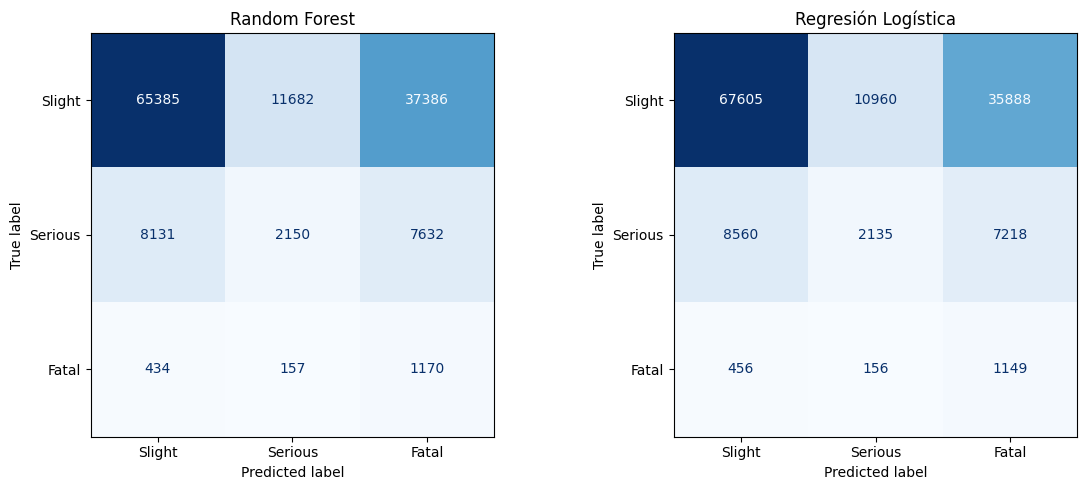

                Random Forest  Regresión Logística
Accuracy                0.512                0.529
F1 macro                0.293                0.298
F1 ponderado            0.611                0.623
Recall Fatal            0.664                0.652
Recall Serious          0.120                0.119


In [28]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score, accuracy_score

etiquetas = ['Slight', 'Serious', 'Fatal']
modelos = {'Random Forest': pred_rf, 'Regresión Logística': pred_lr}

# 1. Reporte de métricas por clase
for nombre, pred in modelos.items():
    print(f"\n===== {nombre} =====")
    print(classification_report(y_test, pred, labels=etiquetas, zero_division=0))

# 2. Matrices de confusión lado a lado
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (nombre, pred) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, labels=etiquetas,
                                            ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(nombre)
plt.tight_layout()
plt.show()

# 3. Tabla resumen para el informe
resumen = pd.DataFrame({
    nombre: {
        'Accuracy': accuracy_score(y_test, pred),
        'F1 macro': f1_score(y_test, pred, average='macro'),
        'F1 ponderado': f1_score(y_test, pred, average='weighted'),
        'Recall Fatal': (pred[y_test == 'Fatal'] == 'Fatal').mean(),
        'Recall Serious': (pred[y_test == 'Serious'] == 'Serious').mean(),
    } for nombre, pred in modelos.items()
}).round(3)
print(resumen)

In [29]:
import joblib
ruta = '/content/drive/MyDrive/Tp5_Accidentes/'
joblib.dump(rf, ruta + 'modelo_rf.joblib', compress=3)
joblib.dump(list(X.columns), ruta + 'columnas.joblib')

# Muestra liviana del dataset para el repositorio
df_modelo.sample(20000, random_state=42).to_csv(ruta + 'muestra_datos.csv', index=False)

import os
print(round(os.path.getsize(ruta + 'modelo_rf.joblib') / 1e6, 1), "MB")

1.2 MB


In [37]:
import sklearn, joblib
print(sklearn.__version__, joblib.__version__)

1.6.1 1.6.0
